# 07 — Análise espacial transversal do ENEM

Este notebook produz exclusivamente **mapas municipais de um único ano**, definido em `ANO_TRANSVERSAL`.

A análise estatística, os rankings, as distribuições e as demais interpretações quantitativas permanecem no notebook 06. Aqui, os resultados são apresentados espacialmente, sem repetir tabelas ou gráficos estatísticos já tratados naquele notebook.

**Regra metodológica:**
- **1998–2008:** mapas de participação e de desempenho em OBJETIVA e Redação antiga. Não são produzidos mapas que comparem qual disciplina tem maior ou menor média, nem mapas de diferença entre disciplinas.
- **2009–2025:** além dos mapas de participação e desempenho por disciplina, são produzidos mapas da disciplina com maior média, da disciplina com menor média e do intervalo entre essas médias, pois as áreas e a Redação seguem a estrutura de avaliação vigente nesse período.


In [1]:
# ============================================================
# 1. IMPORTAÇÕES, CONFIGURAÇÃO E LEITURA
# ============================================================

from _setup import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from matplotlib.colors import LogNorm, Normalize
from matplotlib.patches import Patch

from enem_pipeline.config import PROJECT_ROOT, UF_PROCESSAMENTO
from utils.features_names import read_allfiles
from utils.eda import configuracao_analise_transversal

# ------------------------------------------------------------
# Parâmetros definidos pelo usuário
# ------------------------------------------------------------

UF_PROCESSAMENTO = "PA"
ANO_TRANSVERSAL = 2025  # Escolher qualquer ano entre 1998 e 2025.

if not 1998 <= int(ANO_TRANSVERSAL) <= 2025:
    raise ValueError("ANO_TRANSVERSAL deve estar entre 1998 e 2025.")

ANO_TRANSVERSAL = int(ANO_TRANSVERSAL)

# A configuração do eda.py determina automaticamente as disciplinas válidas.
config_ano = configuracao_analise_transversal(ANO_TRANSVERSAL)

PERIODO_TRANSVERSAL = config_ano["periodo"]
DISCIPLINAS_TRANSVERSAL = config_ano["disciplinas"]
COLUNAS_MEDIAS = config_ano["colunas_medias"]
NOMES_DISCIPLINAS = config_ano["nomes_disciplinas"]
ORDEM_DISCIPLINAS = config_ano["ordem_disciplinas"]

# Uma única leitura. read_allfiles já harmoniza os nomes municipais
# das bases analíticas com a malha geográfica usando o código municipal.
dados_consumo = read_allfiles(UF_PROCESSAMENTO)
painel = dados_consumo["painel"]["data"].copy()
municipios_geo = dados_consumo["shape"]["data"].copy()

print(f"UF: {UF_PROCESSAMENTO}")
print(f"Ano transversal: {ANO_TRANSVERSAL}")
print(f"Período metodológico: {PERIODO_TRANSVERSAL['rotulo']}")
print(f"Estrutura: {PERIODO_TRANSVERSAL['estrutura']}")
print(f"Disciplinas: {', '.join(ORDEM_DISCIPLINAS)}")
print(f"Registros do painel: {len(painel):,}")
print(f"Municípios na malha: {len(municipios_geo):,}")


UF: PA
Ano transversal: 2025
Período metodológico: 2009–2025
Estrutura: AREAS
Disciplinas: REDACAO, CN, CH, LC, MT
Registros do painel: 2,412
Municípios na malha: 144


## 2. Preparação dos dados espaciais

A junção é realizada pelo código municipal. Não há nova normalização de nomes: essa etapa já é executada por `read_allfiles()`.


In [2]:
# ============================================================
# 2. JUNÇÃO PAINEL MUNICIPAL × MALHA GEOGRÁFICA
# ============================================================

COLUNA_CODIGO_PAINEL = "CO_MUNICIPIO_TERRITORIO"
COLUNA_CODIGO_SHAPE = "CD_MUN"

for coluna in [COLUNA_CODIGO_PAINEL, "ano", "n_participantes"]:
    if coluna not in painel.columns:
        raise KeyError(f"Coluna obrigatória ausente no painel: {coluna}")

if COLUNA_CODIGO_SHAPE not in municipios_geo.columns:
    raise KeyError(f"Coluna obrigatória ausente na malha: {COLUNA_CODIGO_SHAPE}")

# Padronização apenas do tipo do código para permitir a junção.
def codigo_municipal_como_texto(serie):
    return (
        serie.astype("string")
        .str.replace(r"\.0$", "", regex=True)
        .str.strip()
    )

painel["_codigo_municipio_join"] = codigo_municipal_como_texto(
    painel[COLUNA_CODIGO_PAINEL]
)
municipios_geo["_codigo_municipio_join"] = codigo_municipal_como_texto(
    municipios_geo[COLUNA_CODIGO_SHAPE]
)

painel_geo = municipios_geo.merge(
    painel,
    on="_codigo_municipio_join",
    how="left",
    validate="one_to_many"
)

dados_ano = painel_geo[
    pd.to_numeric(painel_geo["ano"], errors="coerce") == ANO_TRANSVERSAL
].copy()

if dados_ano.empty:
    raise ValueError(
        f"Não há registros municipais para {UF_PROCESSAMENTO} em {ANO_TRANSVERSAL}."
    )

colunas_ausentes = [c for c in COLUNAS_MEDIAS if c not in dados_ano.columns]
if colunas_ausentes:
    raise KeyError(
        f"Colunas de desempenho ausentes em {ANO_TRANSVERSAL}: {colunas_ausentes}"
    )

print(f"Municípios/registros disponíveis em {ANO_TRANSVERSAL}: {len(dados_ano):,}")


Municípios/registros disponíveis em 2025: 89


## 3. Mapa de participação

Mostra a distribuição espacial do número de participantes por município no ano selecionado. Municípios sem registros permanecem na cor de fundo.


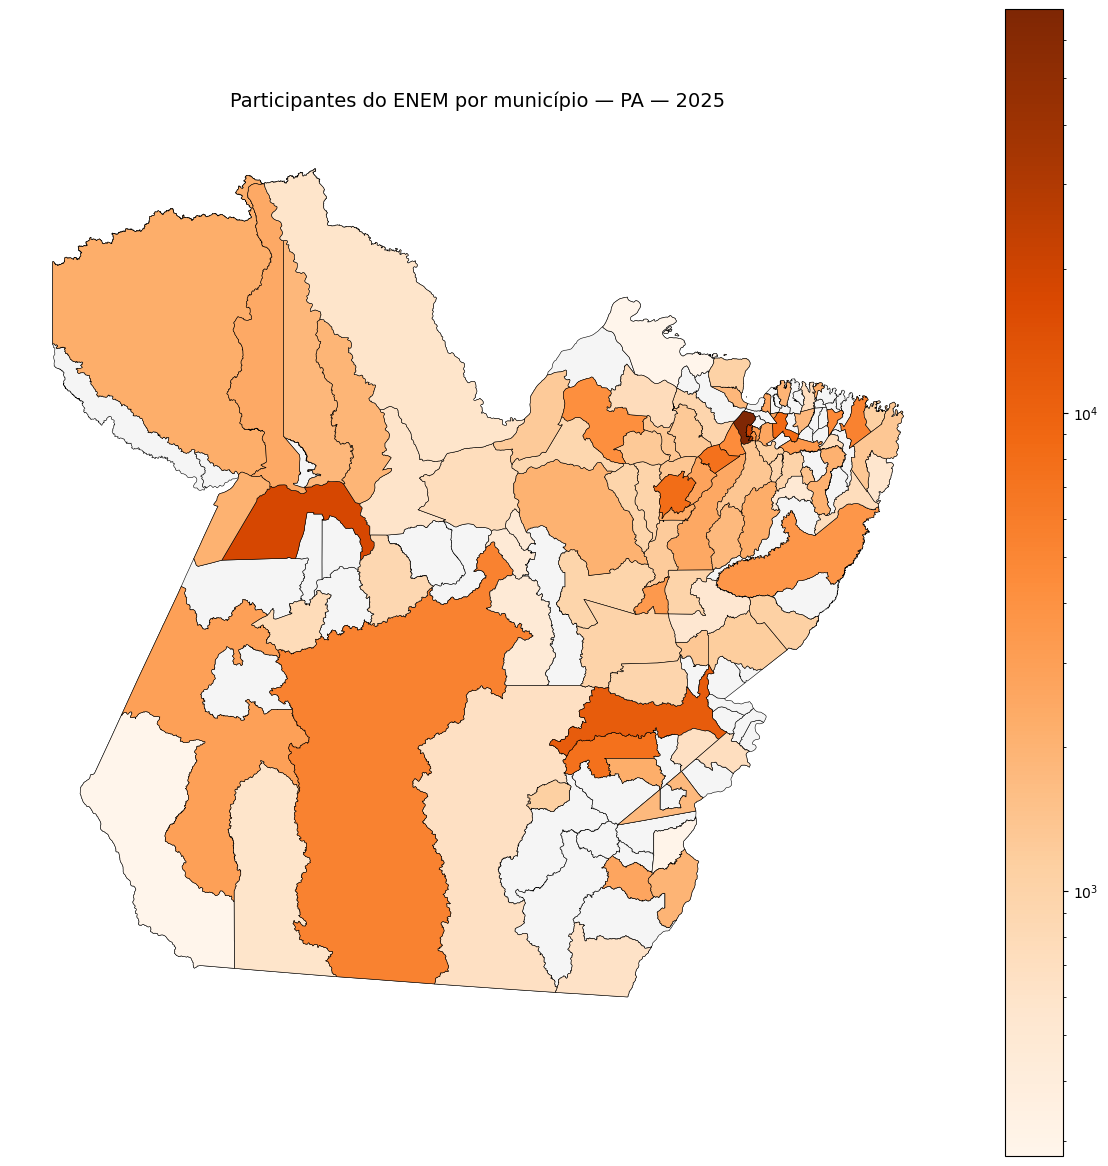

In [3]:
# ============================================================
# 3. MAPA DE PARTICIPAÇÃO
# ============================================================

participacao = dados_ano[
    pd.to_numeric(dados_ano["n_participantes"], errors="coerce").gt(0)
].copy()
participacao["n_participantes"] = pd.to_numeric(
    participacao["n_participantes"], errors="coerce"
)

fig, ax = plt.subplots(figsize=(12, 12))
municipios_geo.plot(
    color="whitesmoke", linewidth=0.4, edgecolor="black", ax=ax
)

if not participacao.empty:
    vmin = participacao["n_participantes"].min()
    vmax = participacao["n_participantes"].max()
    escala = LogNorm(vmin=vmin, vmax=vmax) if vmax > vmin else Normalize(vmin=vmin - 0.5, vmax=vmax + 0.5)

    participacao.plot(
        column="n_participantes",
        cmap="Oranges",
        norm=escala,
        linewidth=0.4,
        edgecolor="black",
        legend=True,
        ax=ax
    )
else:
    print(f"Não há valores positivos de participação em {ANO_TRANSVERSAL}.")

ax.set_title(
    f"Participantes do ENEM por município — {UF_PROCESSAMENTO} — {ANO_TRANSVERSAL}",
    fontsize=14,
    pad=15
)
ax.set_axis_off()
plt.tight_layout()
plt.show()


## 4. Mapas de desempenho médio por disciplina

São apresentados somente os indicadores válidos para o ano escolhido. Cada disciplina recebe seu próprio mapa; não se produz aqui uma tabela ou ranking de desempenho.


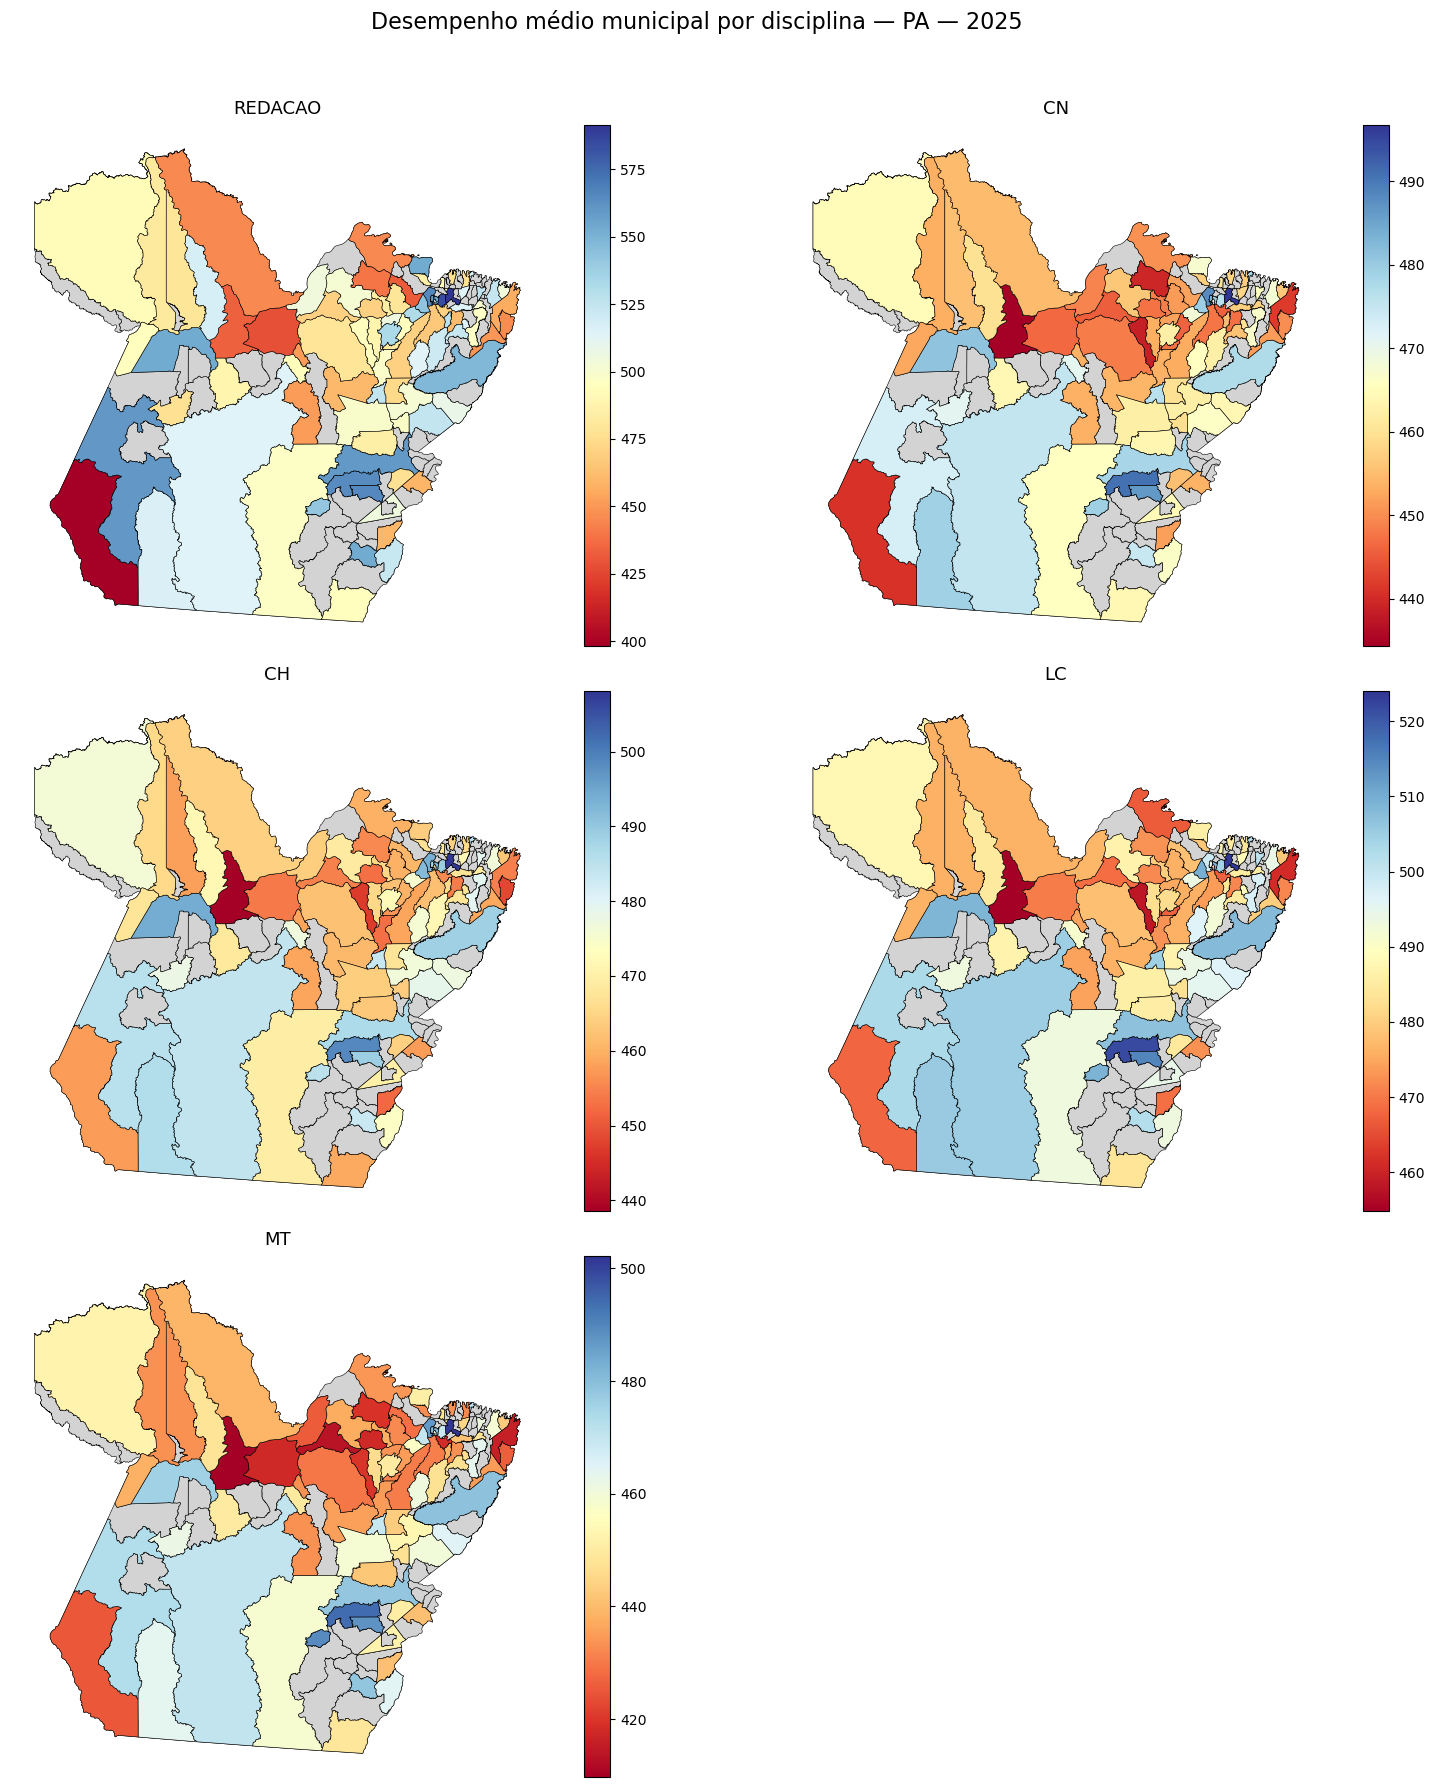

In [4]:
# ============================================================
# 4. MAPAS DE DESEMPENHO MÉDIO POR DISCIPLINA
# ============================================================

n_mapas = len(COLUNAS_MEDIAS)
n_colunas = 2
n_linhas = int(np.ceil(n_mapas / n_colunas))

fig, axes = plt.subplots(
    n_linhas, n_colunas,
    figsize=(16, 6 * n_linhas),
    squeeze=False
)
axes = axes.flatten()

for i, coluna in enumerate(COLUNAS_MEDIAS):
    ax = axes[i]
    dados_disciplina = dados_ano.copy()
    dados_disciplina[coluna] = pd.to_numeric(
        dados_disciplina[coluna], errors="coerce"
    )
    dados_disciplina = dados_disciplina[
        dados_disciplina[coluna].notna()
    ]

    municipios_geo.plot(
        color="lightgray", linewidth=0.4, edgecolor="black", ax=ax
    )

    if dados_disciplina.empty:
        ax.set_title(f"{NOMES_DISCIPLINAS[coluna]} — sem dados")
        ax.set_axis_off()
        continue

    vmin = dados_disciplina[coluna].min()
    vmax = dados_disciplina[coluna].max()
    escala = Normalize(vmin=vmin, vmax=vmax) if vmax > vmin else Normalize(vmin=vmin - 0.5, vmax=vmax + 0.5)

    dados_disciplina.plot(
        column=coluna,
        cmap="RdYlBu",
        norm=escala,
        linewidth=0.4,
        edgecolor="black",
        legend=True,
        ax=ax
    )
    ax.set_title(NOMES_DISCIPLINAS[coluna], fontsize=13, pad=8)
    ax.set_axis_off()

for ax in axes[n_mapas:]:
    ax.remove()

fig.suptitle(
    f"Desempenho médio municipal por disciplina — {UF_PROCESSAMENTO} — {ANO_TRANSVERSAL}",
    fontsize=16,
    y=0.99
)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


## 5. Perfil espacial comparativo das disciplinas — somente 2009–2025

A comparação entre disciplinas é produzida apenas quando o ano selecionado pertence ao período 2009–2025. Para 1998–2008, esta seção é ignorada: não se comparam OBJETIVA e Redação antiga por maior/menor média nem se calcula diferença entre elas.

Os mapas desta seção são cartográficos. As tabelas, estatísticas descritivas e interpretações quantitativas permanecem no notebook 06.


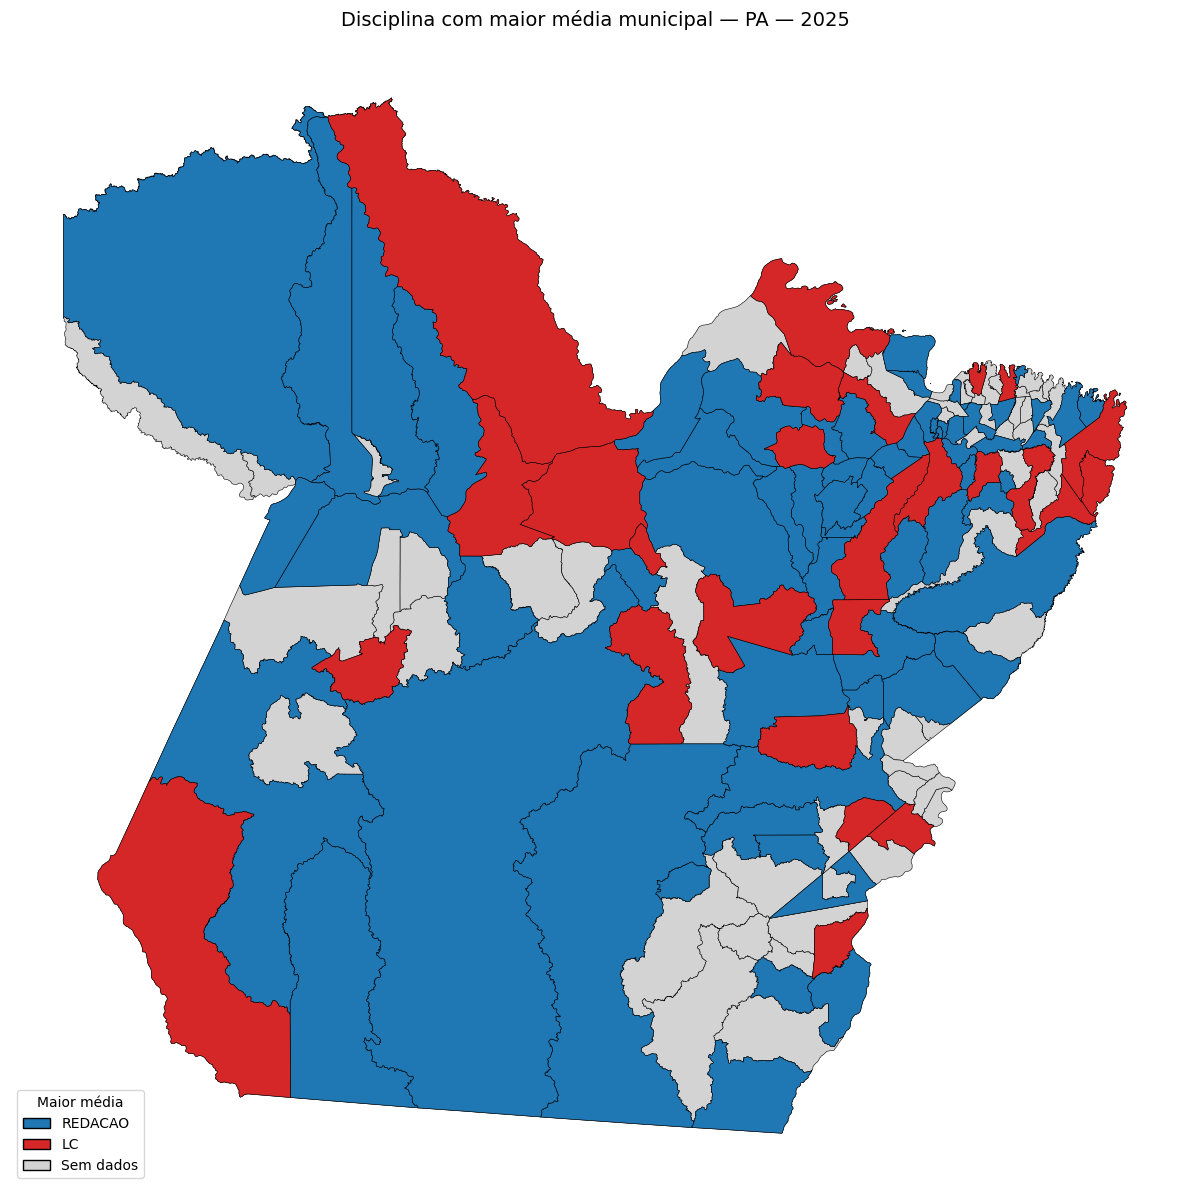

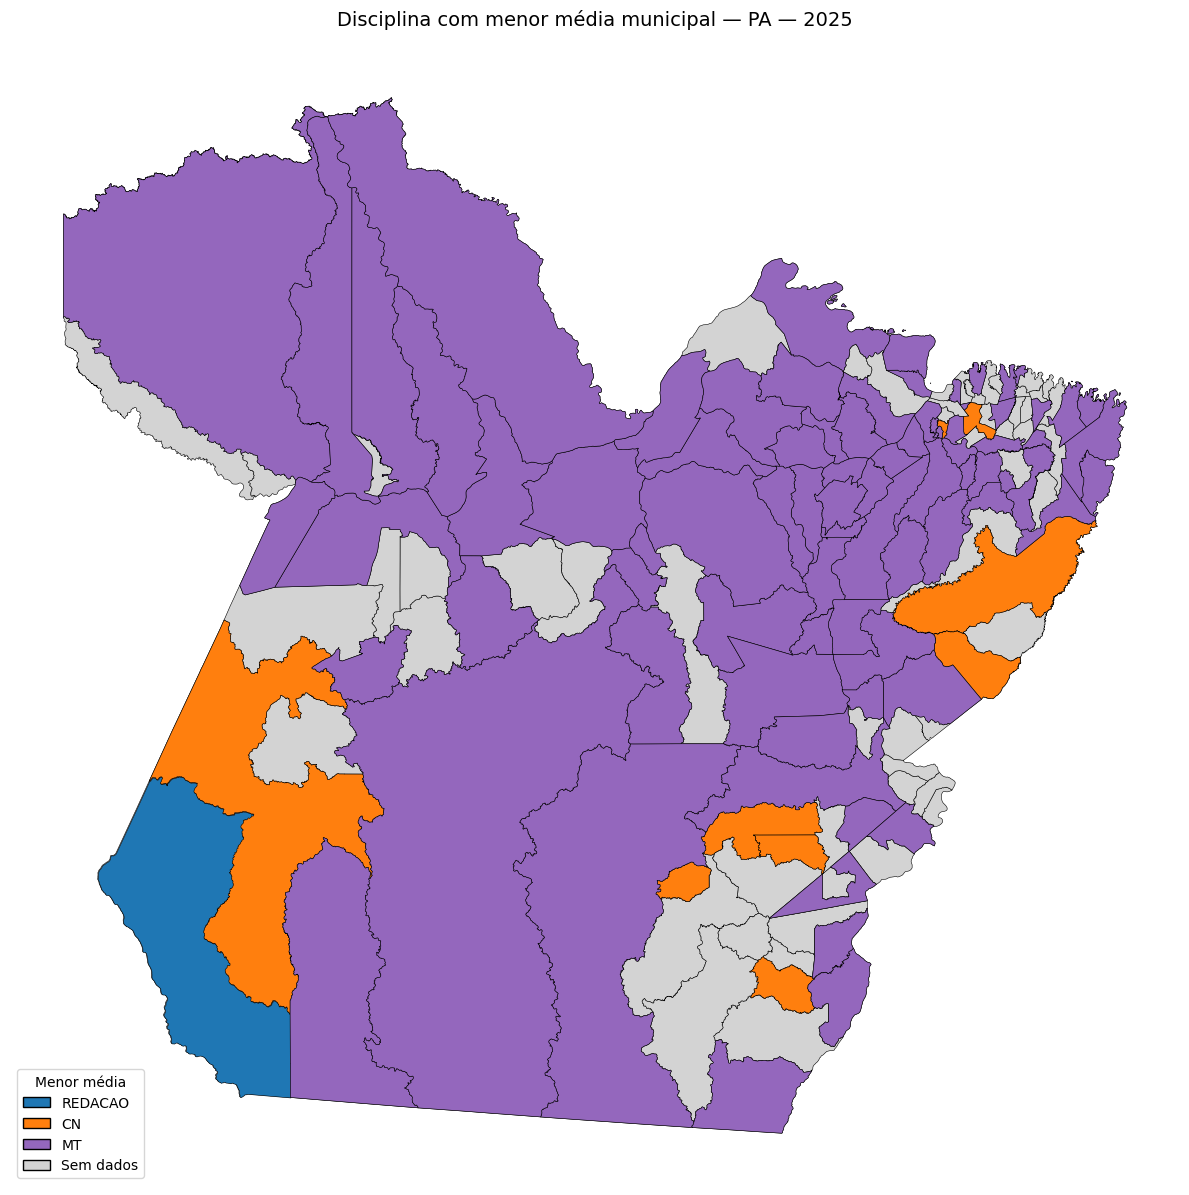

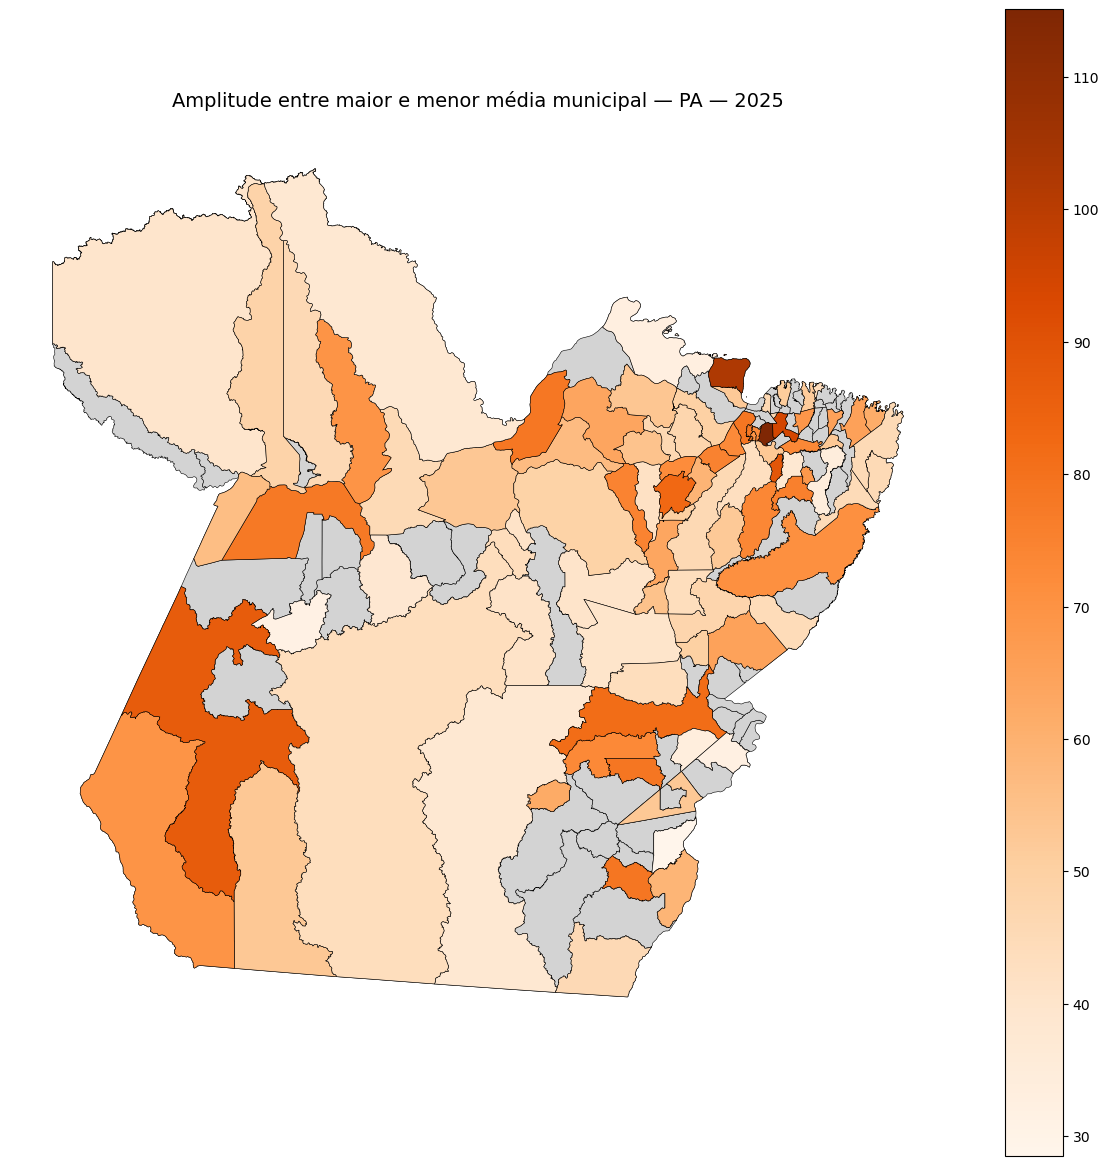

In [5]:
# ============================================================
# 5. MAPAS COMPARATIVOS ENTRE DISCIPLINAS — 2009–2025
# ============================================================

if ANO_TRANSVERSAL < 2009:
    print(
        "Seção não aplicável: entre 1998 e 2008 não são produzidos "
        "mapas de maior/menor média entre disciplinas nem de gap."
    )
else:
    # Usar somente as médias válidas e numéricas do ano selecionado.
    medias = dados_ano[
        [COLUNA_CODIGO_PAINEL, "NO_MUNICIPIO_TERRITORIO"] + COLUNAS_MEDIAS
    ].copy()

    for coluna in COLUNAS_MEDIAS:
        medias[coluna] = pd.to_numeric(medias[coluna], errors="coerce")

    # idxmax/idxmin ignoram NaN; municípios sem nenhuma média válida
    # permanecem sem categoria.
    matriz_medias = medias[COLUNAS_MEDIAS]
    tem_alguma_media = matriz_medias.notna().any(axis=1)

    medias["coluna_maior"] = matriz_medias.idxmax(axis=1)
    medias["coluna_menor"] = matriz_medias.idxmin(axis=1)
    medias["disciplina_maior"] = medias["coluna_maior"].map(NOMES_DISCIPLINAS)
    medias["disciplina_menor"] = medias["coluna_menor"].map(NOMES_DISCIPLINAS)
    medias["gap_media"] = matriz_medias.max(axis=1) - matriz_medias.min(axis=1)

    medias.loc[~tem_alguma_media, [
        "disciplina_maior", "disciplina_menor", "gap_media"
    ]] = np.nan

    # Agregar os resultados à malha pelo código municipal.
    mapa_comparativo = municipios_geo.merge(
        medias[
            [
                COLUNA_CODIGO_PAINEL,
                "disciplina_maior",
                "disciplina_menor",
                "gap_media"
            ]
        ].assign(
            _codigo_municipio_join=lambda df: codigo_municipal_como_texto(
                df[COLUNA_CODIGO_PAINEL]
            )
        ).drop(columns=[COLUNA_CODIGO_PAINEL]),
        on="_codigo_municipio_join",
        how="left",
        validate="one_to_one"
    )

    # --------------------------------------------------------
    # 5.1. Mapa da disciplina com maior média municipal
    # --------------------------------------------------------
    cores = {
        disciplina: plt.get_cmap("tab10")(i)
        for i, disciplina in enumerate(ORDEM_DISCIPLINAS)
    }

    fig, ax = plt.subplots(figsize=(12, 12))
    mapa_comparativo.plot(
        color="lightgray", linewidth=0.4, edgecolor="black", ax=ax
    )

    for disciplina, cor in cores.items():
        subset = mapa_comparativo[
            mapa_comparativo["disciplina_maior"] == disciplina
        ]
        if not subset.empty:
            subset.plot(
                color=cor, linewidth=0.4, edgecolor="black", ax=ax
            )

    legenda = [
        Patch(facecolor=cor, edgecolor="black", label=disciplina)
        for disciplina, cor in cores.items()
        if (mapa_comparativo["disciplina_maior"] == disciplina).any()
    ]
    legenda.append(Patch(facecolor="lightgray", edgecolor="black", label="Sem dados"))
    ax.legend(handles=legenda, title="Maior média", loc="lower left")
    ax.set_title(
        f"Disciplina com maior média municipal — {UF_PROCESSAMENTO} — {ANO_TRANSVERSAL}",
        fontsize=14, pad=15
    )
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 5.2. Mapa da disciplina com menor média municipal
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(12, 12))
    mapa_comparativo.plot(
        color="lightgray", linewidth=0.4, edgecolor="black", ax=ax
    )

    for disciplina, cor in cores.items():
        subset = mapa_comparativo[
            mapa_comparativo["disciplina_menor"] == disciplina
        ]
        if not subset.empty:
            subset.plot(
                color=cor, linewidth=0.4, edgecolor="black", ax=ax
            )

    legenda = [
        Patch(facecolor=cor, edgecolor="black", label=disciplina)
        for disciplina, cor in cores.items()
        if (mapa_comparativo["disciplina_menor"] == disciplina).any()
    ]
    legenda.append(Patch(facecolor="lightgray", edgecolor="black", label="Sem dados"))
    ax.legend(handles=legenda, title="Menor média", loc="lower left")
    ax.set_title(
        f"Disciplina com menor média municipal — {UF_PROCESSAMENTO} — {ANO_TRANSVERSAL}",
        fontsize=14, pad=15
    )
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # 5.3. Mapa do gap entre a maior e a menor média
    # --------------------------------------------------------
    fig, ax = plt.subplots(figsize=(12, 12))
    mapa_comparativo.plot(
        color="lightgray", linewidth=0.4, edgecolor="black", ax=ax
    )

    dados_gap = mapa_comparativo[
        pd.to_numeric(mapa_comparativo["gap_media"], errors="coerce").notna()
    ].copy()

    if not dados_gap.empty:
        dados_gap.plot(
            column="gap_media",
            cmap="Oranges",
            linewidth=0.4,
            edgecolor="black",
            legend=True,
            ax=ax
        )

    ax.set_title(
        f"Amplitude entre maior e menor média municipal — {UF_PROCESSAMENTO} — {ANO_TRANSVERSAL}",
        fontsize=14, pad=15
    )
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()


## 6. Encerramento

Este notebook termina após gerar os mapas do ano selecionado. Não realiza comparações temporais entre anos, não produz séries históricas e não substitui as análises estatísticas do notebook 06.

**Leitura metodológica:** para 1998–2008, a seção comparativa entre disciplinas não é executada. Para 2009–2025, os mapas de maior média, menor média e amplitude são apresentados apenas como representação espacial do ano escolhido.
